# BPIC-17 — Section 2.2: Simple Event Log Analysis

Assignment I, *Business Process Prediction, Simulation, and Optimization* (TUM, WS 2026/27).

This notebook computes
1. the **required statistics** of Section 2.2 (Table 1 of the report, `tables/basic_stats.csv`),
2. an **attribute overview** (case vs. event level, data type, categorical or not),
3. a breakdown of the three event types **A_ (Application), O_ (Offer), W_ (Workflow)**,
4. two **additional statistics** (variant coverage; case outcome and throughput time; Table 2 of the
   report) with figures (`figures/*.pdf`).

**Data:** BPI Challenge 2017 application log (van Dongen, 2017), DOI
[10.4121/uuid:5f3067df-f10b-45da-b98b-86ae4c7a310b](https://doi.org/10.4121/uuid:5f3067df-f10b-45da-b98b-86ae4c7a310b).
The XES file is expected at `BPIC-17 Data/BPI Challenge 2017.xes`.

## 0. Setup

In [1]:
from pathlib import Path
import platform
import time

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import pm4py

np.random.seed(42)

DATA_DIR = Path("BPIC-17 Data")
XES_PATH = DATA_DIR / "BPI Challenge 2017.xes"
CACHE_PATH = DATA_DIR / "bpic17_eventlog.pkl"   
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
TAB_DIR = Path("tables"); TAB_DIR.mkdir(exist_ok=True)

CASE, ACT, TS = "case:concept:name", "concept:name", "time:timestamp"
LC, RES, ORIGIN = "lifecycle:transition", "org:resource", "EventOrigin"

OUTCOME_COLORS = {"Pending": "#2a78d6", "Denied": "#eb6834", "Cancelled": "#1baf7a", "None (open)": "#b4b2a9"}
INK, INK2, GRID = "#1f1f1e", "#5f5e58", "#e4e3de"
mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False, "lines.linewidth": 2,
})

def savefig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.pdf")

print("Python", platform.python_version(), "| pm4py", pm4py.__version__, "| pandas", pd.__version__,
      "| numpy", np.__version__, "| matplotlib", mpl.__version__)



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




Python 3.11.0 | pm4py 2.7.23.12 | pandas 3.1.1 | numpy 2.4.6 | matplotlib 3.11.2


## 1. Load the event log

`pm4py.read_xes` converts the XES log into a pandas DataFrame (one row per event). Case-level
attributes get the prefix `case:`. Parsing takes a few minutes, so the result is cached as a pickle.

Events are sorted by case, timestamp and original file order (stable sort), so events with equal
timestamps keep their order from the XES file.

In [2]:
if CACHE_PATH.exists():
    df = pd.read_pickle(CACHE_PATH)
    print("Loaded cached DataFrame from", CACHE_PATH)
else:
    t0 = time.time()
    df = pm4py.read_xes(str(XES_PATH))
    print(f"Parsed XES in {time.time() - t0:.0f} s")
    df.to_pickle(CACHE_PATH)

df[TS] = pd.to_datetime(df[TS], utc=True)
df["_order"] = np.arange(len(df))
df = df.sort_values([CASE, TS, "_order"], kind="stable").reset_index(drop=True)
print(df.shape)
df.head(8)

Loaded cached DataFrame from BPIC-17 Data/bpic17_eventlog.pkl


(1202267, 20)


,Action,org:resource,concept:name,EventOrigin,EventID,lifecycle:transition,time:timestamp,case:LoanGoal,case:ApplicationType,case:concept:name,case:RequestedAmount,FirstWithdrawalAmount,NumberOfTerms,Accepted,MonthlyCost,Selected,CreditScore,OfferedAmount,OfferID,_order
0,Created,User_1,A_Create Application,Application,Application_1000086665,complete,2016-08-03 15:57:21.673+00:00,"Other, see explanation",New credit,Application_1000086665,5000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,686058
1,statechange,User_1,A_Submitted,Application,ApplState_161925113,complete,2016-08-03 15:57:21.734+00:00,"Other, see explanation",New credit,Application_1000086665,5000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,686059
2,Created,User_1,W_Handle leads,Workflow,Workitem_747707399,schedule,2016-08-03 15:57:21.963+00:00,"Other, see explanation",New credit,Application_1000086665,5000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,686060
3,Deleted,User_1,W_Handle leads,Workflow,Workitem_1030261128,withdraw,2016-08-03 15:58:28.286+00:00,"Other, see explanation",New credit,Application_1000086665,5000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,686061
4,Created,User_1,W_Complete application,Workflow,Workitem_1127124826,schedule,2016-08-03 15:58:28.293+00:00,"Other, see explanation",New credit,Application_1000086665,5000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,686062
5,statechange,User_1,A_Concept,Application,ApplState_385184570,complete,2016-08-03 15:58:28.299+00:00,"Other, see explanation",New credit,Application_1000086665,5000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,686063
6,Obtained,User_14,W_Complete application,Workflow,Workitem_518019192,start,2016-08-04 13:39:29.557+00:00,"Other, see explanation",New credit,Application_1000086665,5000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,686064
7,Released,User_14,W_Complete application,Workflow,Workitem_1967765821,suspend,2016-08-04 13:50:12.281+00:00,"Other, see explanation",New credit,Application_1000086665,5000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,686065


## 2. Attribute overview

* **Case attributes** are the columns with prefix `case:` (one value per case, taken from the first row of each case).
* **Event attributes** are all other columns (helper columns starting with `_` or `@@` are excluded).
* **Type:** `timestamp`, `numeric`, `boolean` or `string`. **Categorical** means `string` or `boolean`
  (a finite set of labels, not a measured quantity). `EventID` and `OfferID` are categorical, but they are
  identifiers, so the table reports the count with and without them.
* `present in` lists the event origins (A_/O_/W_) where the attribute has a value. This shows which attributes belong to which event type.

In [3]:
HELPER = [c for c in df.columns if c.startswith("_") or c.startswith("@@")]
case_attrs = [c for c in df.columns if c.startswith("case:") and c not in HELPER]
event_attrs = [c for c in df.columns if not c.startswith("case:") and c not in HELPER]
cases_df = df.drop_duplicates(CASE)[case_attrs]          # one row per case

def attr_type(s: pd.Series) -> str:
    if pd.api.types.is_datetime64_any_dtype(s):
        return "timestamp"
    if pd.api.types.is_bool_dtype(s):
        return "boolean"
    if pd.api.types.is_numeric_dtype(s):
        return "numeric"
    vals = s.dropna().unique()
    if len(vals) and all(isinstance(v, (bool, np.bool_)) for v in vals):
        return "boolean"
    return "string"

rows = []
for level, attrs, frame in [("case", case_attrs, cases_df), ("event", event_attrs, df)]:
    for a in attrs:
        s = frame[a]
        rows.append({
            "attribute": a, "level": level, "type": attr_type(s),
            "distinct values": s.nunique(dropna=True),
            "missing %": round(100 * s.isna().mean(), 1),
            "present in": "all cases" if level == "case"
                          else ", ".join(sorted(df.loc[s.notna(), ORIGIN].unique())),
        })
attr_overview = pd.DataFrame(rows)
attr_overview["categorical"] = attr_overview["type"].isin(["string", "boolean"])
attr_overview

,attribute,level,type,distinct values,missing %,present in,categorical
0,case:LoanGoal,case,string,14,0.0,all cases,True
1,case:ApplicationType,case,string,2,0.0,all cases,True
2,case:concept:name,case,string,31509,0.0,all cases,True
3,case:RequestedAmount,case,numeric,701,0.0,all cases,False
4,Action,event,string,5,0.0,"Application, Offer, Workflow",True
5,org:resource,event,string,149,0.0,"Application, Offer, Workflow",True
6,concept:name,event,string,26,0.0,"Application, Offer, Workflow",True
7,EventOrigin,event,string,3,0.0,"Application, Offer, Workflow",True
8,EventID,event,string,1202267,0.0,"Application, Offer, Workflow",True
9,lifecycle:transition,event,string,7,0.0,"Application, Offer, Workflow",True


In [4]:
IDENTIFIERS = {"EventID", "OfferID"}
cat_event = attr_overview.query("level == 'event' and categorical")["attribute"].tolist()
cat_event_no_id = [a for a in cat_event if a not in IDENTIFIERS]
print("Case attributes  :", case_attrs)
print("Event attributes :", event_attrs)
print(f"Categorical event attributes ({len(cat_event)}):", cat_event)
print(f"  without identifiers ({len(cat_event_no_id)}):", cat_event_no_id)

Case attributes  : ['case:LoanGoal', 'case:ApplicationType', 'case:concept:name', 'case:RequestedAmount']
Event attributes : ['Action', 'org:resource', 'concept:name', 'EventOrigin', 'EventID', 'lifecycle:transition', 'time:timestamp', 'FirstWithdrawalAmount', 'NumberOfTerms', 'Accepted', 'MonthlyCost', 'Selected', 'CreditScore', 'OfferedAmount', 'OfferID']
Categorical event attributes (9): ['Action', 'org:resource', 'concept:name', 'EventOrigin', 'EventID', 'lifecycle:transition', 'Accepted', 'Selected', 'OfferID']
  without identifiers (7): ['Action', 'org:resource', 'concept:name', 'EventOrigin', 'lifecycle:transition', 'Accepted', 'Selected']


## 3. Required statistics (Section 2.2)

* **Case length** is the number of events per case.
* **Case duration** is the time from the first to the last event of a case. The same mean and standard
  deviation are expressed in days, minutes and seconds.
* **Variant** is the ordered sequence of activity names of a case. Lifecycle transitions are not part
  of the activity name, so `W_Validate application` (start) and (complete) count as the same label.
* **Standard deviation** uses the sample definition (pandas default, ddof = 1).
* Distinct case attribute labels include `case:concept:name` (the case ID).

In [5]:
n_cases = df[CASE].nunique()
case_len = df.groupby(CASE).size()
bounds = df.groupby(CASE)[TS].agg(["min", "max"])
case_dur_s = (bounds["max"] - bounds["min"]).dt.total_seconds()
traces = df.groupby(CASE, sort=False)[ACT].agg(tuple)
variant_counts = traces.value_counts()

# cross-check with pm4py's own variant computation
n_variants_pm4py = len(pm4py.get_variants(df, activity_key=ACT, case_id_key=CASE, timestamp_key=TS))
print("variants (pandas):", len(variant_counts), "| variants (pm4py):", n_variants_pm4py)

variants (pandas): 15930 | variants (pm4py): 15930


In [6]:
SEC_PER = {"days": 86_400, "minutes": 60, "seconds": 1}

stats = [
    ("Number of cases", f"{n_cases:,}"),
    ("Number of events", f"{len(df):,}"),
    ("Number of process variants", f"{len(variant_counts):,}"),
    ("Number of distinct activities", f"{df[ACT].nunique()}"),
    ("Number of distinct case attribute labels", f"{len(case_attrs)}"),
    ("Number of distinct event attribute labels", f"{len(event_attrs)}"),
    ("Case length (events): mean / std", f"{case_len.mean():.2f} / {case_len.std():.2f}"),
    ("Case length (events): median [min, max]", f"{case_len.median():.0f} [{case_len.min()}, {case_len.max()}]"),
]
for unit, k in SEC_PER.items():
    stats.append((f"Case duration ({unit}): mean / std",
                  f"{case_dur_s.mean() / k:,.2f} / {case_dur_s.std() / k:,.2f}"))
stats += [
    ("Case duration (days): median", f"{case_dur_s.median() / 86_400:.2f}"),
    ("Number of categorical event attributes", f"{len(cat_event)} ({len(cat_event_no_id)} excl. identifiers)"),
    ("Number of resources", f"{df[RES].nunique()}"),
    ("Observation period", f"{df[TS].min():%Y-%m-%d} to {df[TS].max():%Y-%m-%d}"),
]
basic_stats = pd.DataFrame(stats, columns=["Statistic", "Value"])
basic_stats.to_csv(TAB_DIR / "basic_stats.csv", index=False)
basic_stats

,Statistic,Value
0,Number of cases,"31,509"
1,Number of events,"1,202,267"
2,Number of process variants,"15,930"
3,Number of distinct activities,26
4,Number of distinct case attribute labels,4
5,Number of distinct event attribute labels,15
6,Case length (events): mean / std,38.16 / 16.72
7,"Case length (events): median [min, max]","35 [10, 180]"
8,Case duration (days): mean / std,21.90 / 13.17
9,Case duration (minutes): mean / std,"31,535.43 / 18,963.69"


## 4. The three event types: A_ (Application), O_ (Offer), W_ (Workflow)

The prefix of each activity name matches the `EventOrigin` attribute:

| Prefix | `EventOrigin` | What it records |
|---|---|---|
| `A_` | Application | state change of the **loan application** (e.g., submitted, accepted, complete, pending, denied, cancelled) |
| `O_` | Offer | state change of an **offer** made for that application; one application can have several offers (`OfferID`) |
| `W_` | Workflow | a **work item** (task) that an employee processes, with lifecycle transitions schedule → start → suspend/resume → complete (or withdraw / ate_abort) |

A_ and O_ events are instantaneous status updates and have only the `complete` transition. W_ events describe
work over time, so their lifecycle carries waiting times (schedule → start) and processing times (start → complete).
The tables below verify this on the data.

In [7]:
origin_summary = df.groupby(ORIGIN).agg(
    events=(ACT, "size"), activities=(ACT, "nunique"), cases=(CASE, "nunique"), resources=(RES, "nunique"))
origin_summary.insert(1, "% of events", (100 * origin_summary["events"] / len(df)).round(1))
origin_summary["lifecycle transitions"] = df.groupby(ORIGIN)[LC].agg(lambda s: ", ".join(sorted(s.unique())))
origin_summary["Action values"] = df.groupby(ORIGIN)["Action"].agg(lambda s: ", ".join(sorted(s.dropna().unique())))
origin_summary

,events,% of events,activities,cases,resources,lifecycle transitions,Action values
EventOrigin,,,,,,,
Application,239595,19.9,10,31509,144,complete,"Created, statechange"
Offer,193849,16.1,8,31509,144,complete,"Created, statechange"
Workflow,768823,63.9,8,31509,149,"ate_abort, complete, resume, schedule, start, ...","Created, Deleted, Obtained, Released"


In [8]:
act_table = (df.groupby(ACT)
               .agg(origin=(ORIGIN, "first"), events=(CASE, "size"), cases=(CASE, "nunique"))
               .assign(**{"% of cases": lambda x: (100 * x["cases"] / n_cases).round(1),
                          "events per case (if present)": lambda x: (x["events"] / x["cases"]).round(2)})
               .sort_values(["origin", "cases"], ascending=[True, False]))
act_table

,origin,events,cases,% of cases,events per case (if present)
concept:name,,,,,
A_Accepted,Application,31509,31509,100.0,1.00
A_Concept,Application,31509,31509,100.0,1.00
A_Create Application,Application,31509,31509,100.0,1.00
A_Complete,Application,31362,31362,99.5,1.00
A_Validating,Application,38816,21870,69.4,1.77
A_Submitted,Application,20423,20423,64.8,1.00
A_Pending,Application,17228,17228,54.7,1.00
A_Incomplete,Application,23055,15003,47.6,1.54
A_Cancelled,Application,10431,10431,33.1,1.00


Lifecycle transitions of the W_ work items (event counts):

In [9]:
w = df[df[ORIGIN] == "Workflow"]
pd.crosstab(w[ACT], w[LC], margins=True, margins_name="total")

lifecycle:transition,ate_abort,complete,resume,schedule,start,suspend,withdraw,total
concept:name,,,,,,,,
W_Assess potential fraud,42,282,996,327,355,1277,3,3282
W_Call after offers,31085,342,29130,34656,31485,61218,3176,191092
W_Call incomplete files,20220,2793,39201,23055,23218,60042,0,168529
W_Complete application,10565,19104,22652,31532,29918,33266,1863,148900
W_Handle leads,151,3493,1247,20446,3727,1398,16802,47264
W_Personal Loan collection,0,0,7,2,4,9,0,22
W_Shortened completion,0,0,7,74,76,81,0,238
W_Validate application,23161,15848,33920,39012,39444,58111,0,209496
total,85224,41862,127160,149104,128227,215402,21844,768823


### Example case

The example is a successful case (outcome `A_Pending`) with exactly one offer and a length close to the median.
It shows how A_, O_ and W_ events interleave within one application.

In [10]:
OUTCOME_ACTS = ["A_Pending", "A_Denied", "A_Cancelled"]
last_outcome = (df[df[ACT].isin(OUTCOME_ACTS)].groupby(CASE)[ACT].last()
                  .str.replace("A_", "", regex=False))
outcome = last_outcome.reindex(case_len.index).fillna("None (open)")
offers = df[df[ACT] == "O_Create Offer"].groupby(CASE).size().reindex(case_len.index, fill_value=0)

cand = case_len[(outcome == "Pending") & (offers == 1)]
example_id = (cand - case_len.median()).abs().sort_values(kind="stable").index[0]
cols = [TS, ACT, LC, RES, "OfferID"]
print("Example case:", example_id, "| events:", case_len[example_id])
df.loc[df[CASE] == example_id, cols].reset_index(drop=True)

Example case: Application_1003639640 | events: 35


,time:timestamp,concept:name,lifecycle:transition,org:resource,OfferID
0,2016-01-26 11:31:07.592+00:00,A_Create Application,complete,User_10,NaN
1,2016-01-26 11:31:07.596+00:00,A_Concept,complete,User_10,NaN
2,2016-01-26 11:31:07.607+00:00,W_Complete application,schedule,User_10,NaN
3,2016-01-26 11:31:07.609+00:00,W_Complete application,start,User_10,NaN
4,2016-01-26 11:32:08.247+00:00,A_Accepted,complete,User_10,NaN
5,2016-01-26 11:33:38.422+00:00,O_Create Offer,complete,User_10,NaN
6,2016-01-26 11:33:39.644+00:00,O_Created,complete,User_10,Offer_669337617
7,2016-01-26 11:33:52.593+00:00,O_Sent (mail and online),complete,User_10,Offer_669337617
8,2016-01-26 11:33:52.608+00:00,W_Complete application,complete,User_10,NaN
9,2016-01-26 11:33:52.615+00:00,W_Call after offers,schedule,User_10,NaN


## 5. Additional statistics

Two additional statistics are reported. Both support later sections:

* **5.1 Variant coverage** justifies the abstraction level used for discovery (Section 2.3: W_ work items,
  O_ offers, the online submission and the A_ outcome, 16 activities).
* **5.2 Case outcome and throughput time** motivates the outcome block of the final model (Section 2.3)
  and the outcome / duration comparison of the clusters (Section 2.4).

### 5.1 Variant coverage at four abstraction levels

How many of the most frequent variants are needed to cover x % of the cases? Four views are compared:
(a) the full log, (b) only `complete` lifecycle events, (c) only A_ and O_ events, and (d) the level of the
process model in Section 2.3: W_, O_ and A_ events with 16 activities, one event per W_ work item
(`src/abstraction_w.py`). This directly informs the filtering decisions in Section 2.3
(target: replay about 80 % of the cases).

In [11]:
from src.abstraction_w import build_log

abstractions = {
    "Full log": df,
    "Only 'complete' events": df[df[LC].str.lower() == "complete"],
    "Only A_ and O_ events": df[df[ORIGIN].isin(["Application", "Offer"])],
    "W_, O_ and A_ (16 activities)": build_log(df)[0],  # all cases, like the other rows
}
cov_rows, curves = [], {}
for name, frame in abstractions.items():
    tr = frame.groupby(CASE, sort=False)[ACT].agg(tuple)
    vc = tr.value_counts()
    cum = 100 * vc.cumsum().to_numpy() / len(tr)
    curves[name] = cum
    cov_rows.append({
        "abstraction": name, "cases": len(tr), "events": len(frame), "variants": len(vc),
        "top-1 variant % cases": round(cum[0], 1),
        "top-10 variants % cases": round(cum[min(9, len(cum) - 1)], 1),
        "variants for 50 % cases": int(np.searchsorted(cum, 50) + 1),
        "variants for 80 % cases": int(np.searchsorted(cum, 80) + 1),
        "singleton variants": int((vc == 1).sum()),
    })
coverage = pd.DataFrame(cov_rows).set_index("abstraction")
coverage.to_csv(TAB_DIR / "variant_coverage.csv")
coverage

,cases,events,variants,top-1 variant % cases,top-10 variants % cases,variants for 50 % cases,variants for 80 % cases,singleton variants
abstraction,,,,,,,,
Full log,31509,1202267,15930,3.4,15.3,1103,9629,13907
Only 'complete' events,31509,475306,5623,7.0,31.2,35,610,4150
Only A_ and O_ events,31509,433444,2630,16.2,56.7,8,65,1835
"W_, O_ and A_ (16 activities)",31509,361008,2912,11.9,48.5,11,100,1998


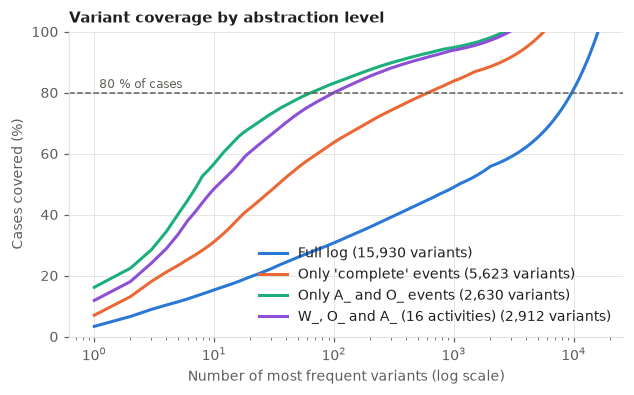

In [12]:
line_colors = ["#2a78d6", "#eb6834", "#1baf7a", "#8c4fd6"]
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for (name, cum), c in zip(curves.items(), line_colors):
    k = np.arange(1, len(cum) + 1)
    ax.plot(k, cum, color=c, label=f"{name} ({len(cum):,} variants)")
ax.axhline(80, color=INK2, linewidth=1, linestyle="--")
ax.text(1.1, 81.5, "80 % of cases", color=INK2, fontsize=8)
ax.set_xscale("log")
ax.set_ylim(0, 100)
ax.set_xlabel("Number of most frequent variants (log scale)")
ax.set_ylabel("Cases covered (%)")
ax.set_title("Variant coverage by abstraction level")
ax.legend(loc="lower right")
savefig(fig, "variant_coverage")
plt.show()

### 5.2 Case outcome and throughput time

The outcome is the **last** of `A_Pending` (loan granted), `A_Denied` (rejected by the bank) and
`A_Cancelled` (cancelled by the customer or automatically). Cases without any of these are still open at the end of the log.

In [13]:
dur_days = case_dur_s / 86_400
outcome_table = (pd.DataFrame({"outcome": outcome, "days": dur_days})
                   .groupby("outcome")["days"]
                   .agg(cases="size", mean="mean", median="median", std="std")
                   .round(2)
                   .sort_values("cases", ascending=False))
outcome_table.insert(1, "% of cases", (100 * outcome_table["cases"] / n_cases).round(1))
outcome_table.to_csv(TAB_DIR / "outcome_throughput.csv")
outcome_table

,cases,% of cases,mean,median,std
outcome,,,,,
Pending,17228,54.7,18.13,14.82,11.69
Cancelled,10431,33.1,29.89,31.61,12.45
Denied,3752,11.9,16.80,14.09,10.78
None (open),98,0.3,28.69,27.00,21.00


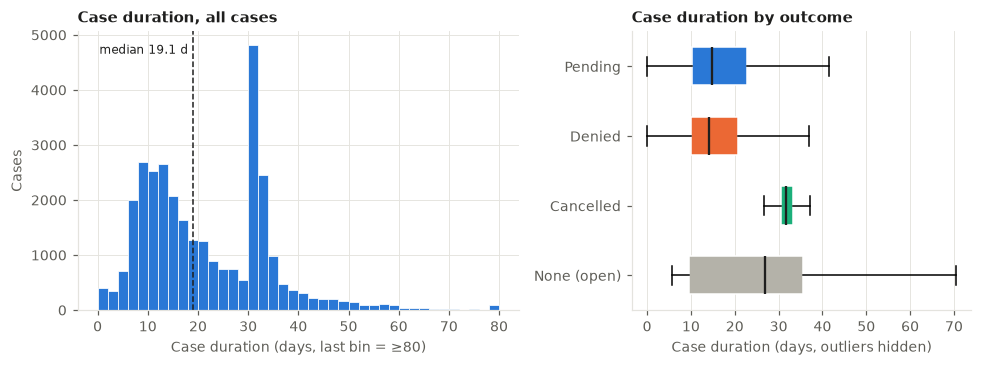

In [14]:
order = [o for o in ["Pending", "Denied", "Cancelled", "None (open)"] if o in outcome_table.index]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.4), gridspec_kw={"width_ratios": [1.3, 1]})

clip = 80
ax1.hist(dur_days.clip(upper=clip), bins=np.arange(0, clip + 2, 2), color="#2a78d6",
         edgecolor="white", linewidth=0.5)
ax1.axvline(dur_days.median(), color=INK, linewidth=1, linestyle="--")
ax1.text(dur_days.median() - 1, ax1.get_ylim()[1] * 0.92, f"median {dur_days.median():.1f} d", fontsize=8, ha="right")
ax1.set_xlabel(f"Case duration (days, last bin = ≥{clip})")
ax1.set_ylabel("Cases")
ax1.set_title("Case duration, all cases")

data = [dur_days[outcome == o] for o in order]
bp = ax2.boxplot(data, orientation="horizontal", tick_labels=order, showfliers=False, widths=0.55,
                 patch_artist=True, medianprops={"color": INK, "linewidth": 1.5})
for patch, o in zip(bp["boxes"], order):
    patch.set_facecolor(OUTCOME_COLORS[o]); patch.set_edgecolor("white")
ax2.invert_yaxis()
ax2.grid(axis="y", visible=False)
ax2.set_xlabel("Case duration (days, outliers hidden)")
ax2.set_title("Case duration by outcome")
fig.tight_layout()
savefig(fig, "case_duration")
plt.show()

### 5.3 Report table

Both additional statistics in one table (Table 2 of the report; the LaTeX version is written by
`src/report_assets.py`): panel (a) variant coverage,
panel (b) case outcome and case duration in days.
Short column names keep the table within the page width; "Top-10 variants (%)" is the share of cases covered by the ten most frequent variants.

In [15]:
def fmt_int(x):
    return f"{int(x):,}"

cov_cols = ["Events", "Variants", "Top-10 variants (%)", "Variants for 80 %"]
cov_report = pd.DataFrame({
    "Events": coverage["events"].map(fmt_int),
    "Variants": coverage["variants"].map(fmt_int),
    "Top-10 variants (%)": coverage["top-10 variants % cases"].map("{:.1f}".format),
    "Variants for 80 %": coverage["variants for 80 % cases"].map(fmt_int),
})
out_cols = ["Cases", "% of cases", "Median (days)", "Mean / std (days)"]
out_report = pd.DataFrame({
    "Cases": outcome_table["cases"].map(fmt_int),
    "% of cases": outcome_table["% of cases"].map("{:.1f}".format),
    "Median (days)": outcome_table["median"].map("{:.1f}".format),
    "Mean / std (days)": [f"{m:.1f} / {s:.1f}" for m, s in zip(outcome_table["mean"], outcome_table["std"])],
})

# the LaTeX version of these tables is written by src/report_assets.py

display(cov_report.rename_axis("Abstraction"))
display(out_report.rename_axis("Outcome"))

,Events,Variants,Top-10 variants (%),Variants for 80 %
Abstraction,,,,
Full log,"1,202,267","15,930",15.3,"9,629"
Only 'complete' events,"475,306","5,623",31.2,610
Only A_ and O_ events,"433,444","2,630",56.7,65
"W_, O_ and A_ (16 activities)","361,008","2,912",48.5,100


,Cases,% of cases,Median (days),Mean / std (days)
Outcome,,,,
Pending,"17,228",54.7,14.8,18.1 / 11.7
Cancelled,"10,431",33.1,31.6,29.9 / 12.4
Denied,"3,752",11.9,14.1,16.8 / 10.8
None (open),98,0.3,27.0,28.7 / 21.0


## 6. Exported files

* `tables/basic_stats.csv`: required statistics (Table 1 of the report)
* `tables/variant_coverage.csv`, `tables/outcome_throughput.csv`: the two additional statistics (Table 2)
* `figures/variant_coverage.pdf`, `figures/case_duration.pdf`: figures of the additional statistics

In [16]:
sorted(p.name for p in FIG_DIR.iterdir()), sorted(p.name for p in TAB_DIR.iterdir())

(['.DS_Store',
  'case_duration.pdf',
  'clustering',
  'discovery',
  'final_model.pdf',
  'final_model_decisions.pdf',
  'variant_coverage.pdf'],
 ['basic_stats.csv',
  'decision_mining.csv',
  'decision_mining_with_leaking.csv',
  'decision_rules.txt',
  'discovery_quality.csv',
  'discovery_top_unfit.csv',
  'dm_leakage.csv',
  'outcome_throughput.csv',
  'variant_coverage.csv',
  'w_level_activities.csv',
  'w_level_dfg.csv',
  'w_level_o_cancelled.csv',
  'w_level_pair_check.csv',
  'w_level_table2a.csv'])